# Bivariate Analysis

## Objective

The objective of this notebook is to study the relationship between two variables using statistical techniques and visualizations.

The analysis covers:

1. Numerical vs Numerical
2. Numerical vs Categorical
3. Categorical vs Categorical

The notebook uses scatter plots, box plots, violin plots, grouped bar charts, and cross tabulation to identify and explain relationships between variables.

## Dataset

The Online Retail II dataset is used for the analysis.

**Important Rule:** Each analysis must use two variables at a time. Every observation must be based on the actual output of the analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "online_retail_II.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


# Topic 1: Numerical vs Numerical

## Step 1: Understand the Concept

Numerical vs Numerical analysis is a type of bivariate analysis used to study the relationship between two numerical variables.

It helps us understand whether changes in one variable are associated with changes in another variable.

The relationship may be:

- **Positive Relationship:** Both variables tend to increase together.
- **Negative Relationship:** One variable tends to increase as the other decreases.
- **No Clear Relationship:** No clear pattern is visible between the two variables.

In this topic, we analyze `Quantity` and `Price` from the Online Retail II dataset.

- `Quantity`: The number of items recorded in a transaction line.
- `Price`: The unit price of an item.

The objective is to examine whether quantity and unit price show any visible relationship in the dataset.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following hypothetical data:

| Quantity | Price |
|---:|---:|
| 1 | 10 |
| 2 | 20 |
| 3 | 30 |
| 4 | 40 |

In this example, both variables increase together, showing a positive relationship.

### Real-World Example

A retail analyst can study the relationship between the number of items purchased and their unit prices.

### Business Example

A business can inspect transaction data to understand whether large quantities are associated with particular unit-price ranges.

### AI/ML Use Case

Numerical relationship analysis helps data scientists understand feature relationships, detect unusual observations, and assess potential input features before model development.

### Technique: Scatter Plot

A scatter plot displays individual observations as points.

- The X-axis represents `Quantity`.
- The Y-axis represents `Price`.
- Each point represents one transaction line.

### Importance in Data Analysis

A scatter plot helps identify visible trends, clusters, and unusual observations. However, a visible relationship does not prove that one variable causes changes in another.

**Univariate vs Bivariate:** Unlike Notebook 4, this analysis uses two variables: `Quantity` and `Price`.

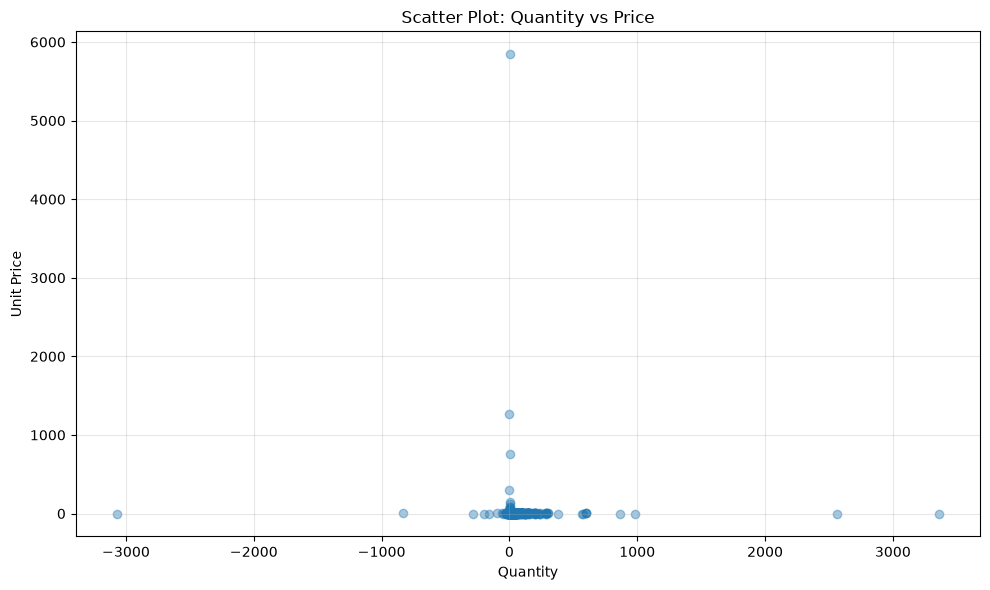

In [2]:
# Select the two numerical variables
bivariate_data = df[["Quantity", "Price"]].copy()

# Convert values to numeric and handle invalid entries
bivariate_data["Quantity"] = pd.to_numeric(
    bivariate_data["Quantity"],
    errors="coerce"
)

bivariate_data["Price"] = pd.to_numeric(
    bivariate_data["Price"],
    errors="coerce"
)

# Remove missing and infinite values
bivariate_data = bivariate_data.dropna()

bivariate_data = bivariate_data[
    np.isfinite(bivariate_data["Quantity"])
    & np.isfinite(bivariate_data["Price"])
]

# Sample observations if the dataset is very large
if len(bivariate_data) > 5000:
    plot_data = bivariate_data.sample(
        n=5000,
        random_state=42
    )
else:
    plot_data = bivariate_data

# Create the scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["Quantity"],
    plot_data["Price"],
    alpha=0.4
)

plt.title("Scatter Plot: Quantity vs Price")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select the Variables

`df[["Quantity", "Price"]].copy()` selects the two variables required for the analysis.

### 2. Convert Values to Numeric

`pd.to_numeric(..., errors="coerce")` converts valid values to numeric form and replaces invalid values with missing values.

### 3. Handle Missing and Infinite Values

`dropna()` removes rows with missing values in the selected columns.

`np.isfinite()` helps exclude infinite values that cannot be meaningfully plotted.

### 4. Sample the Data

If more than 5,000 valid records are available, `sample()` selects 5,000 observations using `random_state=42` so the sample is reproducible.

Sampling improves readability and plotting performance for large datasets. The resulting chart represents the selected sample rather than every record.

### 5. Create the Scatter Plot

`plt.scatter()` plots each observation as a point.

- `plot_data["Quantity"]` supplies the X-axis values.
- `plot_data["Price"]` supplies the Y-axis values.
- `alpha=0.4` makes overlapping points easier to see.

The title, axis labels, and grid make the graph easier to interpret.

### How to Interpret the Output

After running the code, inspect the actual scatter plot.

- An upward pattern may suggest a positive relationship.
- A downward pattern may suggest a negative relationship.
- A widely scattered pattern without a clear direction may suggest a weak or unclear relationship.
- Isolated points may indicate unusual observations that need further investigation.

Retail data may contain returns, negative quantities, zero prices, or extreme values. Do not automatically remove them without understanding their meaning.

### Impact on the ML Pipeline

Understanding relationships between numerical variables helps with exploratory data analysis, anomaly investigation, and feature selection.

**Observation:** Write the relationship you actually see in your graph. Do not assume that `Quantity` and `Price` have a positive or negative relationship before inspecting the result.

# Topic 2: Numerical vs Categorical

## Step 1: Understand the Concept

Numerical vs Categorical analysis studies how the distribution of a numerical variable changes across different categories of a categorical variable.

A numerical variable contains measurable values, while a categorical variable represents groups or labels.

In this analysis, we use:

- `Country`: A categorical variable representing the country recorded in a transaction.
- `Quantity`: A numerical variable representing the number of items recorded in a transaction line.

The objective is to examine how quantity values are distributed across different countries.

A box plot helps summarize the median, quartiles, spread, and potential outliers of a numerical variable within each category.

## Step 2: Demonstrate the Concept

### Simple Example

Consider this hypothetical data:

| Country | Quantity |
|---|---:|
| France | 2 |
| France | 4 |
| France | 6 |
| Germany | 1 |
| Germany | 3 |
| Germany | 5 |

A box plot can show the distribution of quantities within each country category.

### Real-World Example

A retail analyst can examine how the quantities recorded per transaction line vary across countries.

### Business Example

A business can investigate whether some country categories tend to have higher or more variable transaction-line quantities.

### AI/ML Use Case

Comparing a numerical feature across categories helps data scientists understand group-level distributions and identify unusual observations before model development.

### Technique: Box Plot

A box plot displays:

- **Median:** The middle value of the distribution.
- **Quartiles:** Values that divide the data into four parts.
- **Interquartile Range (IQR):** The distance between the third and first quartiles.
- **Whiskers and potential outliers:** Help show the spread and unusually distant observations.

### Importance in Data Analysis

A box plot makes it easier to compare the spread and center of numerical values across categories.

**Bivariate Analysis Rule:** Use exactly two variables here: `Country` and `Quantity`.

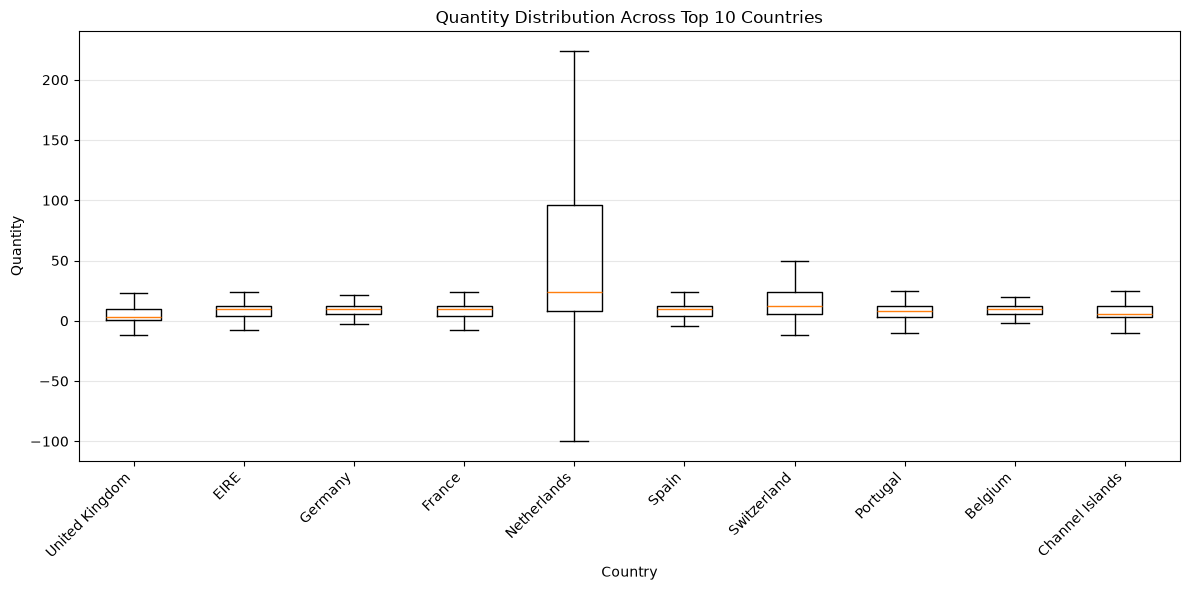

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Select the two variables
bivariate_data = df[["Country", "Quantity"]].copy()

# Convert Quantity to numeric
bivariate_data["Quantity"] = pd.to_numeric(
    bivariate_data["Quantity"],
    errors="coerce"
)

# Remove missing and infinite values
bivariate_data = bivariate_data.dropna(
    subset=["Country", "Quantity"]
)

bivariate_data = bivariate_data[
    np.isfinite(bivariate_data["Quantity"])
]

# Select the 10 most frequent countries for readability
top_countries = (
    bivariate_data["Country"]
    .value_counts()
    .head(10)
    .index
)

plot_data = bivariate_data[
    bivariate_data["Country"].isin(top_countries)
]

# Prepare quantities separately for each country
country_groups = [
    plot_data.loc[
        plot_data["Country"] == country,
        "Quantity"
    ].values
    for country in top_countries
]

# Create the box plot
plt.figure(figsize=(12, 6))

plt.boxplot(
    country_groups,
    tick_labels=top_countries,
    showfliers=False
)

plt.title("Quantity Distribution Across Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Quantity")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select the Variables

`df[["Country", "Quantity"]].copy()` selects only the categorical variable `Country` and the numerical variable `Quantity`.

### 2. Clean the Selected Data

`pd.to_numeric()` converts quantity values to numeric form.

`dropna()` removes records missing either selected value, and `np.isfinite()` excludes infinite quantity values.

### 3. Select the Top 10 Countries

`value_counts().head(10)` identifies the ten countries with the most records.

Using these categories keeps the chart readable. The analysis therefore displays only these ten countries, not every country in the dataset.

### 4. Prepare the Data for the Box Plot

The list comprehension creates a separate collection of quantity values for each selected country.

This allows the box plot to show the distribution of `Quantity` within each country category.

### 5. Create the Box Plot

`plt.boxplot()` creates one box for each country.

- `tick_labels=top_countries` labels the boxes.
- `showfliers=False` hides individual potential outlier markers to improve readability. It does not remove those observations from the data used to calculate the box plots.

### How to Interpret the Output

Compare the median lines and box heights across the displayed countries.

- A higher median indicates a higher middle quantity value.
- A taller box indicates a larger interquartile range.
- Longer whiskers indicate a wider spread beyond the box.
- Because outlier markers are hidden, this chart does not display individual outliers.

Write your observation only after viewing the actual graph. Quantity can include negative values for returns or corrections, so interpret the results in the context of retail transactions.

### Impact on the ML Pipeline

This analysis helps identify differences in numerical distributions across categories and may guide further data-quality checks and feature engineering.

**Variables analyzed: `Country` and `Quantity` only.**

# Topic 3: Violin Plot

## Step 1: Understand the Concept

A violin plot is a visualization used to understand the distribution of a numerical variable across categories.

It combines features of a box plot with a density-based shape that shows where values are more concentrated.

The wider parts of a violin indicate ranges where observations have a higher estimated density. The narrower parts indicate ranges with a lower estimated density.

In this analysis, we use:

- `Country`: A categorical variable.
- `Quantity`: A numerical variable.

The objective is to examine how quantity distributions and their shapes differ across selected countries.

A violin plot helps identify differences in distribution shape, concentration, and spread. Its density shape is an estimate, not a direct count of observations at each value.

## Step 2: Demonstrate the Concept

### Simple Example

Consider these hypothetical quantities:

| Country | Quantity |
|---|---:|
| France | 2 |
| France | 3 |
| France | 3 |
| France | 4 |
| Germany | 1 |
| Germany | 5 |
| Germany | 8 |
| Germany | 10 |

France's values are concentrated within a narrow range, while Germany's values cover a wider range.

A violin plot may show these differences through the shape and width of each distribution.

### Real-World Example

A retail analyst can examine how transaction-line quantities are distributed across countries.

### Business Example

A business can investigate whether quantity values are concentrated around a particular range or spread across a wider range in different countries.

### AI/ML Use Case

Violin plots help data scientists inspect feature distributions across categories and identify skewed or differently shaped distributions.

### Technique: Violin Plot

The width of each violin represents estimated density at different quantity values. Greater width indicates greater estimated concentration around that value.

### Importance in Data Analysis

A violin plot reveals distribution patterns that may not be obvious from a median or a single summary statistic.

**Bivariate Analysis Rule:** Analyze only `Country` and `Quantity` in this plot.

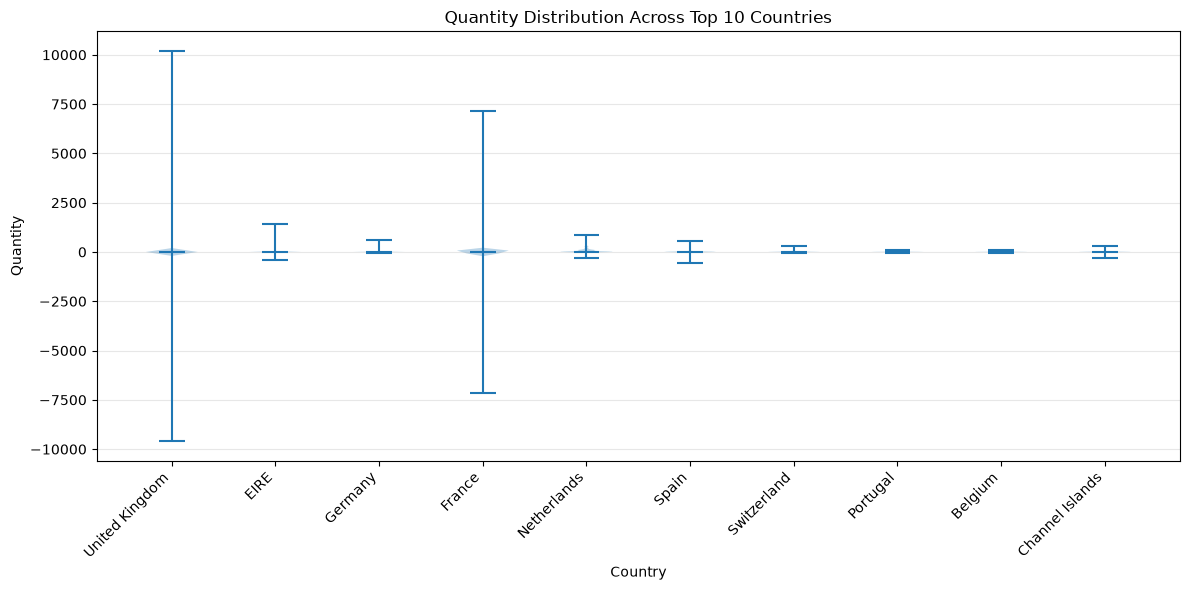

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Select the two variables
bivariate_data = df[["Country", "Quantity"]].copy()

# Convert Quantity to numeric
bivariate_data["Quantity"] = pd.to_numeric(
    bivariate_data["Quantity"],
    errors="coerce"
)

# Remove missing and infinite values
bivariate_data = bivariate_data.dropna(
    subset=["Country", "Quantity"]
)

bivariate_data = bivariate_data[
    np.isfinite(bivariate_data["Quantity"])
]

# Select the 10 most frequent countries
top_countries = (
    bivariate_data["Country"]
    .value_counts()
    .head(10)
    .index
)

plot_data = bivariate_data[
    bivariate_data["Country"].isin(top_countries)
]

# Prepare quantity values for each country
country_groups = [
    plot_data.loc[
        plot_data["Country"] == country,
        "Quantity"
    ].values
    for country in top_countries
]

# Create the violin plot
plt.figure(figsize=(12, 6))

plt.violinplot(
    country_groups,
    showmedians=True,
    showextrema=True
)

plt.title("Quantity Distribution Across Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Quantity")

plt.xticks(
    ticks=range(1, len(top_countries) + 1),
    labels=top_countries,
    rotation=45,
    ha="right"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select the Variables

`df[["Country", "Quantity"]].copy()` selects only the two variables required for the analysis.

### 2. Clean the Data

`pd.to_numeric()` converts `Quantity` into numeric values.

`dropna()` removes missing values, and `np.isfinite()` excludes infinite values.

### 3. Select the Top 10 Countries

`value_counts().head(10)` selects the ten countries with the highest record counts to keep the plot readable.

### 4. Group Quantity Values

The list comprehension creates one array of quantity values for each selected country.

These arrays are passed to the violin plot so that each country has its own distribution.

### 5. Create the Violin Plot

`plt.violinplot()` creates the distribution shapes.

- `showmedians=True` displays the median of each distribution.
- `showextrema=True` displays the minimum and maximum markers and lines supported by the plot.
- `plt.xticks()` labels each violin with its corresponding country.

### How to Interpret the Output

Inspect the width and shape of each violin.

- Wider regions indicate higher estimated density around those quantity values.
- Narrower regions indicate lower estimated density.
- The median marker indicates the middle quantity value.
- Different shapes suggest that quantity distributions vary across the selected countries.

The plot uses only the ten selected countries. Write your observation based on the graph you actually obtain; do not assume that one country has higher quantities before examining the result.

### Impact on the ML Pipeline

Violin plots help reveal differences in feature distributions across categories. These findings can guide further data investigation and preprocessing decisions.

**Variables analyzed: `Country` and `Quantity` only.**

# Topic 4: Categorical vs Categorical — Cross Tabulation

## Step 1: Understand the Concept

Categorical vs Categorical analysis is used to study the relationship between two categorical variables.

Cross tabulation, also called a contingency table, summarizes the frequency of combinations of categories from two variables.

Each row represents a category of the first variable, and each column represents a category of the second variable. The cells show how many records belong to each category combination.

In this analysis, we use:

- `Country`: The country recorded for a transaction.
- `Description`: The product description recorded for a transaction line.

The objective is to examine how product descriptions are distributed across selected countries.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following hypothetical data:

| Country | Description |
|---|---|
| France | Blue Mug |
| France | Red Plate |
| France | Blue Mug |
| Germany | Blue Mug |
| Germany | Coffee Cup |

The cross-tabulation table would be:

| Country | Blue Mug | Red Plate | Coffee Cup |
|---|---:|---:|---:|
| France | 2 | 1 | 0 |
| Germany | 1 | 0 | 1 |

The values show the number of records for each country and product-description combination.

### Real-World Example

A retail analyst can examine how product descriptions appear across different countries.

### Business Example

A business can use cross tabulation to summarize recorded product activity across geographic categories.

### AI/ML Use Case

Cross tabulation helps data scientists inspect associations between categorical features before deciding whether further statistical analysis is useful.

### Importance in Data Analysis

Cross tabulation converts combinations of categorical values into a structured frequency table that is easier to inspect.

**Bivariate Analysis Rule:** Use only `Country` and `Description` in this analysis.

In [6]:
# Select the two categorical variables
categorical_data = df[["Country", "Description"]].copy()

# Remove records with missing values in either variable
categorical_data = categorical_data.dropna(
    subset=["Country", "Description"]
)

# Select the 5 most frequent countries
top_countries = (
    categorical_data["Country"]
    .value_counts()
    .head(5)
    .index
)

# Select the 10 most frequent product descriptions
top_descriptions = (
    categorical_data["Description"]
    .value_counts()
    .head(10)
    .index
)

# Keep records belonging to the selected categories
selected_data = categorical_data[
    categorical_data["Country"].isin(top_countries)
    & categorical_data["Description"].isin(top_descriptions)
]

# Create the cross-tabulation table
cross_tab = pd.crosstab(
    selected_data["Country"],
    selected_data["Description"]
)

print("Cross Tabulation: Country vs Description")
display(cross_tab)

Cross Tabulation: Country vs Description


Description,60 TEATIME FAIRY CAKE CASES,ASSORTED COLOUR BIRD ORNAMENT,HOME BUILDING BLOCK WORD,JUMBO BAG RED RETROSPOT,LUNCH BAG RED SPOTTY,PACK OF 72 RETRO SPOT CAKE CASES,REGENCY CAKESTAND 3 TIER,REX CASH+CARRY JUMBO SHOPPER,STRAWBERRY CERAMIC TRINKET BOX,WHITE HANGING HEART T-LIGHT HOLDER
Country,,,,,,,,,,
EIRE,58,12,13,5,18,49,80,0,28,41
France,12,15,5,21,33,32,16,4,13,4
Germany,7,6,5,20,14,30,49,0,35,5
Netherlands,5,7,0,7,16,10,11,0,0,23
United Kingdom,1278,1381,1347,1237,1157,1293,2005,1222,1730,3433


## Code Explanation

### 1. Select the Variables

`df[["Country", "Description"]].copy()` selects the two categorical variables required for the analysis.

### 2. Handle Missing Values

`dropna()` removes records where either country or description is missing.

### 3. Select Categories

`value_counts().head(5)` selects the five most frequent countries.

`value_counts().head(10)` selects the ten most frequent product descriptions.

These selections keep the table manageable. The resulting table does not represent every country or description in the dataset.

### 4. Filter the Records

`isin()` checks whether each value belongs to the selected categories. The `&` operator keeps records that satisfy both conditions.

### 5. Create the Cross Tabulation

`pd.crosstab()` counts records for each combination of `Country` and `Description`.

- Rows represent countries.
- Columns represent product descriptions.
- Cell values represent record counts.

### How to Interpret the Output

A larger cell count means that the corresponding country-description combination appears more frequently in the selected records.

A zero means that the combination does not appear in the filtered data.

Do not assume that a higher count means higher sales revenue or more individual customers. This table counts transaction-line records.

### Impact on the ML Pipeline

Cross tabulation helps inspect categorical feature combinations and identify patterns that may deserve further investigation.

**Variables analyzed: `Country` and `Description` only.**

# Topic 5: Grouped Bar Chart

## Step 1: Understand the Concept

A grouped bar chart is a visualization used to compare values across categories of two categorical variables.

Bars are arranged in groups so that the values for different categories can be compared within each group.

In this analysis, we use:

- `Country`: A categorical variable representing the country recorded in a transaction.
- `Description`: A categorical variable representing the product description.

The objective is to compare the frequency of selected product descriptions across selected countries.

A grouped bar chart makes it easier to visually compare category combinations than inspecting a large frequency table alone.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following hypothetical data:

| Country | Blue Mug | Red Plate |
|---|---:|---:|
| France | 5 | 3 |
| Germany | 2 | 4 |

A grouped bar chart displays two bars for France and two bars for Germany, one for each product description.

This makes it easier to compare the counts of the selected product descriptions across countries.

### Real-World Example

A retail analyst can compare how frequently selected product descriptions appear in transaction records from different countries.

### Business Example

A business can identify differences in recorded product activity across geographic categories and decide whether further investigation is needed.

### AI/ML Use Case

Grouped bar charts help data scientists inspect combinations of categorical features before feature engineering or further statistical analysis.

### Importance in Data Analysis

Grouped bar charts provide a visual comparison of frequency counts across two categorical variables.

**Bivariate Analysis Rule:** Use only `Country` and `Description` to create this chart.

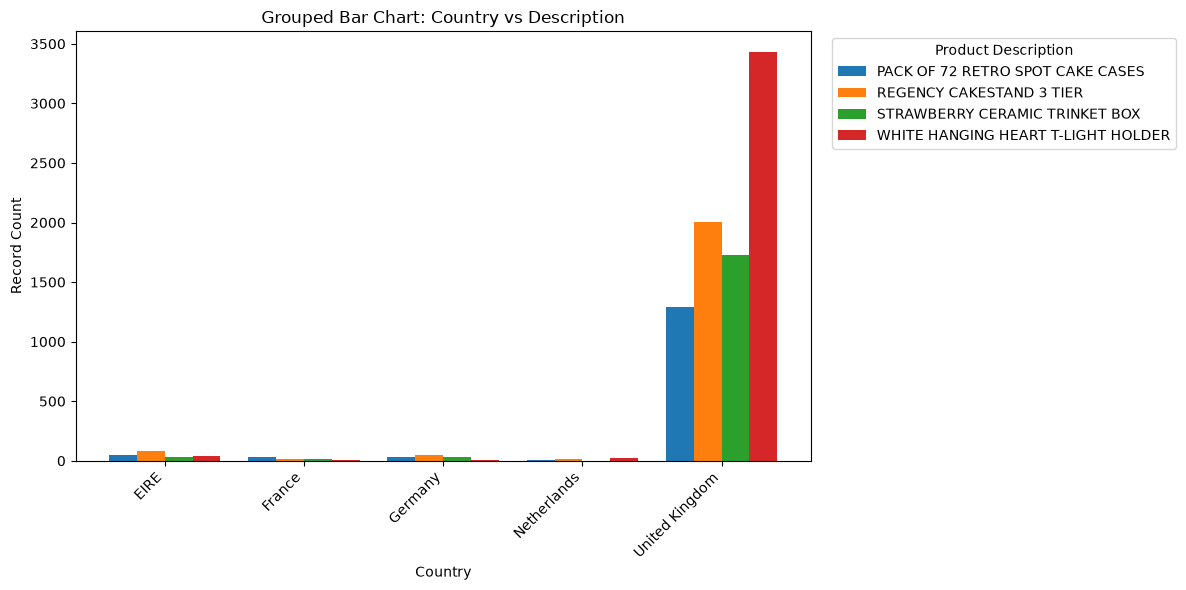

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Select the two categorical variables
categorical_data = df[["Country", "Description"]].dropna()

# Select the 5 most frequent countries
top_countries = (
    categorical_data["Country"]
    .value_counts()
    .head(5)
    .index
)

# Select the 4 most frequent descriptions
top_descriptions = (
    categorical_data["Description"]
    .value_counts()
    .head(4)
    .index
)

# Filter the selected categories
selected_data = categorical_data[
    categorical_data["Country"].isin(top_countries)
    & categorical_data["Description"].isin(top_descriptions)
]

# Create a frequency table
cross_tab = pd.crosstab(
    selected_data["Country"],
    selected_data["Description"]
)

# Plot grouped bars
x = np.arange(len(cross_tab.index))
bar_width = 0.8 / len(cross_tab.columns)

plt.figure(figsize=(12, 6))

for i, description in enumerate(cross_tab.columns):
    plt.bar(
        x + i * bar_width,
        cross_tab[description].values,
        width=bar_width,
        label=description
    )

plt.title("Grouped Bar Chart: Country vs Description")
plt.xlabel("Country")
plt.ylabel("Record Count")

plt.xticks(
    x + bar_width * (len(cross_tab.columns) - 1) / 2,
    cross_tab.index,
    rotation=45,
    ha="right"
)

plt.legend(title="Product Description", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Code Explanation

### 1. Select the Variables

`df[["Country", "Description"]]` selects the two categorical variables. `dropna()` removes records missing either value.

### 2. Select Categories

`value_counts().head(5)` selects the five most frequent countries.

`value_counts().head(4)` selects the four most frequent product descriptions.

These limits help keep the chart readable. The visualization represents only the selected categories.

### 3. Create the Frequency Table

`pd.crosstab()` counts the records for each country-description combination.

The rows represent countries, the columns represent product descriptions, and the values represent record counts.

### 4. Position the Bars

`np.arange()` creates positions for the country groups.

`bar_width` calculates the width of each bar so that multiple product-description bars can fit within each country group.

### 5. Draw the Grouped Bars

The `for` loop creates one set of bars for each selected product description.

`plt.bar()` draws the bars using the corresponding record counts.

`label=description` identifies each product description in the legend.

### 6. Add Labels and Display

The title and axis labels explain what the chart represents. `plt.legend()` identifies the product-description groups, while `plt.tight_layout()` adjusts the layout before `plt.show()` displays the chart.

### How to Interpret the Output

Compare the bar heights for each selected country and product description.

- A taller bar indicates a higher record count for that combination.
- Differences in bar heights show how the selected description counts vary across the selected countries.
- A missing or zero-height bar indicates no matching records in the filtered data.

Write your observation based on the actual chart. Record count does not directly represent revenue or the number of unique customers.

### Impact on the ML Pipeline

Grouped bar charts help identify patterns between categorical features and guide further exploratory analysis.

**Variables analyzed: `Country` and `Description` only.**

# Final Observations and Conclusion

## 1. Observations

### Numerical vs Numerical — Scatter Plot

The scatter plot was used to examine the relationship between `Quantity` and `Price`. The visible pattern, strength, and any unusual observations should be described based on the actual plot.

**Observation:** Write whether the plot shows a positive, negative, or unclear relationship.

### Numerical vs Categorical — Box Plot

The box plot was used to compare the distribution of `Quantity` across the selected `Country` categories.

**Observation:** Describe the differences you observe in median values, spread, and potential outliers.

### Numerical vs Categorical — Violin Plot

The violin plot was used to inspect the shape and estimated density of `Quantity` distributions across the selected countries.

**Observation:** Describe which distributions appear more concentrated or spread out, based on the plotted shapes.

### Categorical vs Categorical — Cross Tabulation

Cross tabulation was used to count records for combinations of `Country` and `Description`.

**Observation:** Identify any country-description combinations with relatively high or low counts in the displayed table.

### Categorical vs Categorical — Grouped Bar Chart

The grouped bar chart was used to visually compare the counts of selected product descriptions across selected countries.

**Observation:** Describe the differences in bar heights that are visible in the chart.

## 2. Conclusion

Bivariate analysis helps examine relationships between two variables using statistical summaries, visualizations, and frequency tables.

Scatter plots help visualize relationships between numerical variables. Box plots and violin plots compare numerical distributions across categories. Cross tabulation and grouped bar charts summarize and visualize combinations of categorical variables.

These techniques support exploratory data analysis by helping identify patterns, differences, and unusual observations.

All conclusions should be based on the actual outputs obtained from the dataset. A visible association does not necessarily indicate a causal relationship.